# Project 2 — Digital Advertising Budget Optimizer (Daraz Pakistan)
**Continues Project 1: *Pakistani Social Media Content Detective*.**

Project 1 measured *what content* Daraz Pakistan's audience engages with on YouTube (comedy/entertainment ≈ 4.8× the engagement of sale videos).
Project 2 asks management's next question: **where should Daraz spend the next Rs 1 million across Facebook, Instagram, Google, TikTok and YouTube?**

| Step | What happens | Code |
|---|---|---|
| 1 | Simulate 22 months of Daraz ad history (10K → 100K → 1M → 10M records) | `src/generate_data.py` |
| 2 | KPIs: CTR, CPC, CPA, conversion rate, ROAS, revenue, campaign performance | `src/kpis.py` |
| 3 | Big-data benchmark: Pandas vs MapReduce (mrjob) vs Spark | `src/run_engine.py`, `src/mapreduce_job.py`, `src/benchmark.py` |
| 4 | Marketing Budget Recommendation Engine | `src/recommender.py` |

> **Colab:** `Runtime → Run all`. No API key is needed — all data is simulated. Spark needs Java, which Colab already has.

In [1]:
# Setup (Colab: clone the repo first)
import os, sys
if not os.path.exists("src"):
    !git clone -q https://github.com/zuhair142006/daraz-ad-budget-optimizer.git
    %cd daraz-ad-budget-optimizer
!pip install -q pyspark mrjob pyarrow psutil standard-pipes 2>/dev/null
sys.path.insert(0, "src")
import pandas as pd, numpy as np
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
from IPython.display import Image, display

## 1. Data simulation
Meta, TikTok and Google Ads data needs ad-account access (the same wall that stopped Meta data in Project 1), so the history is **simulated** from assumptions in `src/config.py`:

* **5 platforms**, each with its own CPM, CTR, conversion rate, order value and **diminishing returns** (Google search saturates fastest, because search volume is limited).
* **5 campaigns** taken from Daraz.pk's real YouTube content types found in Project 1: *Hansna Mana Hai* comedy, 11.11/12.12 Mega Sale, Ramadan & Eid, Seller Stories/How-to, Always-on Catalogue. Project 1's finding is built in: comedy earns more attention (CTR ×1.6, ×2.1 on YouTube) but converts less directly.
* **Pakistani calendar:** 11.11, 12.12, Pakistan Day sale, Ramadan/Eid 2025–26.
* **Audience:** age, gender, 11 Pakistani cities, Android/iOS/Desktop.

The daily budget (≈ Rs 1M/month, Rs 22M total) is fixed. A bigger dataset is a *finer breakdown* of the same spend, so business totals stay comparable across sizes.

In [2]:
!python src/generate_data.py --rows 10000 100000 1000000 10000000 --out data

  10K:     10,000 rows  spend Rs   20,551,314  revenue Rs    97,660,508  CSV      1.1 MB  (0.1s)


 100K:    100,000 rows  spend Rs   21,994,522  revenue Rs   104,997,514  CSV     10.2 MB  (0.2s)


   1M:  1,000,000 rows  spend Rs   21,994,521  revenue Rs   104,867,688  CSV     98.6 MB  (1.5s)


  10M: 10,000,000 rows  spend Rs   21,994,513  revenue Rs   103,036,949  CSV    966.6 MB  (16.8s)


In [3]:
df = pd.read_parquet("data/daraz_ads_1M.parquet")
print(df.shape); df.head()

(1000000, 12)


,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device
0,2025-01-01,Hansna Mana Hai (Comedy),Facebook,89,1,16.59,0,0,45-54,Male,Karachi,Android
1,2025-01-01,Hansna Mana Hai (Comedy),Facebook,135,4,19.78,0,0,25-34,Male,Lahore,Android
2,2025-01-01,Hansna Mana Hai (Comedy),Facebook,107,3,13.57,0,0,18-24,Male,Karachi,Android
3,2025-01-01,Hansna Mana Hai (Comedy),Facebook,258,4,29.30,0,0,18-24,Male,Karachi,Android
4,2025-01-01,Hansna Mana Hai (Comedy),Facebook,116,3,24.44,0,0,25-34,Male,Lahore,Android


## 2. KPIs
All KPIs are *ratios of sums* (total clicks ÷ total impressions), never averages of row-level ratios.

In [4]:
from kpis import kpi_table
cols = ["spend","revenue","conversions","CTR_%","CPC","CPA","CVR_%","ROAS","spend_share_%"]
plat = kpi_table(df, "platform").sort_values("ROAS", ascending=False)
plat[cols]

,spend,revenue,conversions,CTR_%,CPC,CPA,CVR_%,ROAS,spend_share_%
platform,,,,,,,,,
Google,"4,441,220.60",39054955,10504,2.69,15.42,422.81,3.65,8.79,20.19
Instagram,"4,480,298.19",20930174,7134,1.12,20.29,628.02,3.23,4.67,20.37
Facebook,"6,493,257.46",29109314,12027,1.22,12.97,539.89,2.40,4.48,29.52
TikTok,"3,312,700.89",9500618,5448,1.07,7.82,608.06,1.29,2.87,15.06
YouTube,"3,267,044.13",6272627,2300,0.75,25.04,"1,420.45",1.76,1.92,14.85


In [5]:
kpi_table(df, "campaign").sort_values("ROAS", ascending=False)[cols]

,spend,revenue,conversions,CTR_%,CPC,CPA,CVR_%,ROAS,spend_share_%
campaign,,,,,,,,,
Ramadan & Eid,"1,436,424.67",8110414,2558,1.20,14.40,561.54,2.56,5.65,6.53
11.11 / 12.12 Mega Sale,"3,406,639.35",18832551,7633,1.14,15.00,446.30,3.36,5.53,15.49
Hansna Mana Hai (Comedy),"4,889,496.52",24955647,8654,1.78,9.65,565.00,1.71,5.10,22.23
Always-on Catalogue,"8,582,449.00",42714281,14821,1.08,15.80,579.07,2.73,4.98,39.02
Seller Stories / How-to,"3,679,511.73",10254795,3747,0.87,19.71,981.99,2.01,2.79,16.73


In [6]:
# Campaign performance: platform x campaign ROAS
kpi_table(df, ["platform","campaign"])["ROAS"].unstack().round(2)

campaign,Hansna Mana Hai (Comedy),11.11 / 12.12 Mega Sale,Ramadan & Eid,Seller Stories / How-to,Always-on Catalogue
platform,,,,,
Facebook,4.77,5.23,5.18,2.74,4.66
Instagram,4.95,5.86,5.22,2.58,4.86
Google,9.32,9.71,11.06,5.11,9.31
TikTok,3.07,3.18,3.20,1.76,3.05
YouTube,2.32,2.25,2.25,1.09,1.86


In [7]:
# Audience: where does a rupee work hardest?
for dim in ["city","device","age","gender"]:
    display(kpi_table(df, dim).sort_values("ROAS", ascending=False)[["spend","CTR_%","CVR_%","CPA","ROAS"]].round(2))

,spend,CTR_%,CVR_%,CPA,ROAS
city,,,,,
Islamabad,"1,762,422.84",1.30,2.81,469.85,7.29
Lahore,"4,402,612.83",1.24,2.53,547.25,5.31
Karachi,"4,828,200.90",1.24,2.48,558.24,5.13
Rawalpindi,"1,759,619.68",1.25,2.41,570.75,5.13
Sialkot,"1,325,378.05",1.24,2.40,575.25,4.83
Peshawar,"1,541,412.93",1.18,2.20,662.12,3.83
Gujranwala,"1,313,511.57",1.18,2.22,656.76,3.82
Faisalabad,"1,761,993.24",1.18,2.22,658.44,3.74
Multan,"1,320,402.15",1.17,2.10,693.85,3.56


,spend,CTR_%,CVR_%,CPA,ROAS
device,,,,,
iOS,"2,786,784.10",1.34,2.80,470.58,8.41
Desktop,"2,967,105.59",1.16,3.44,506.07,6.97
Android,"16,240,631.58",1.21,2.17,633.71,3.74


,spend,CTR_%,CVR_%,CPA,ROAS
age,,,,,
35-44,"4,067,841.08",1.19,2.87,551.12,6.02
25-34,"7,825,295.66",1.23,2.84,495.90,5.61
45-54,"1,964,850.42",1.09,2.53,695.28,4.96
55+,"958,590.98",1.05,1.98,937.96,3.37
18-24,"7,177,943.13",1.27,1.77,689.92,3.27


,spend,CTR_%,CVR_%,CPA,ROAS
gender,,,,,
Female,"8,938,957.36",1.25,2.60,535.23,5.43
Male,"13,055,563.91",1.20,2.25,630.34,4.32


In [8]:
# Monthly trend (seasonality: Ramadan + 11.11 / 12.12 peaks)
m = df.assign(month=df.date.astype(str).str[:7])
kpi_table(m, "month")[["spend","revenue","ROAS","CPA"]]

,spend,revenue,ROAS,CPA
month,,,,
2025-01,"910,943.58",4193984,4.60,606.49
2025-02,"868,641.49",3924792,4.52,630.82
2025-03,"1,477,320.75",8018771,5.43,519.63
2025-04,"905,623.59",4166529,4.60,619.44
2025-05,"935,857.60",4386881,4.69,599.14
2025-06,"915,222.01",4251979,4.65,612.60
2025-07,"967,440.13",4376311,4.52,605.79
2025-08,"954,877.32",4370822,4.58,608.98
2025-09,"921,036.99",4053269,4.40,627.41


## 3. Big Data simulation: Pandas vs MapReduce vs Spark
Same query in all three engines — group by platform × campaign, sum the 5 volume columns, compute CTR/CPC/CPA/CVR/ROAS. First check that all three give **identical** answers:

In [9]:
for e in ["pandas","mapreduce","spark"]:
    !python src/run_engine.py --engine {e} --file data/daraz_ads_100K.csv 2>/dev/null
outs = {e: pd.read_csv(f"results/engine_output_{e}_100K_csv.csv") for e in ["pandas","mapreduce","spark"]}
for e in ["mapreduce","spark"]:
    diff = (outs["pandas"][["impressions","clicks","conversions","revenue"]] - outs[e][["impressions","clicks","conversions","revenue"]]).abs().values.max()
    print(f"pandas vs {e}: max difference in totals = {diff}, ROAS diff = {(outs['pandas'].ROAS-outs[e].ROAS).abs().max():.1e}")

{"engine": "pandas", "file": "data/daraz_ads_100K.csv", "groups": 25, "load_s": 0.10615935800001353, "query_s": 0.020133292999844343, "startup_s": 0.0, "total_s": 0.12631528000019898}


{"engine": "mapreduce", "file": "data/daraz_ads_100K.csv", "groups": 25, "load_s": 0.0, "query_s": 2.365126453999892, "startup_s": 0.0, "total_s": 2.578784283999994}


{"engine": "spark", "file": "data/daraz_ads_100K.csv", "groups": 25, "load_s": 0.0, "query_s": 5.066599075999875, "startup_s": 6.06037219000018, "total_s": 11.633993448999945}


pandas vs mapreduce: max difference in totals = 0, ROAS diff = 7.1e-15
pandas vs spark: max difference in totals = 0, ROAS diff = 8.0e-15


In [10]:
# Full benchmark takes ~20 min on 2 cores. Set RUN_BENCHMARK = True to re-run it.
RUN_BENCHMARK = False
if RUN_BENCHMARK:
    !python src/benchmark.py
bench = pd.read_csv("results/benchmark.csv")
bench.pivot_table(index=["engine","format"], columns="size", values="wall_s")[["10K","100K","1M","10M"]]

size                10K  100K    1M   10M
engine    format                         
mapreduce csv      2.35  2.90  7.04 55.76
pandas    csv      0.43  0.54  0.95  7.13
          parquet  0.40  0.43  0.51  1.47
spark     csv     11.26 12.01 13.67 22.11
          parquet 11.55 12.00 12.69 14.28

In [11]:
bench.pivot_table(index=["engine","format"], columns="size", values="peak_mem_mb")[["10K","100K","1M","10M"]]

size                 10K   100K     1M      10M
engine    format                               
mapreduce csv     352.66 352.84 352.90   607.46
pandas    csv     118.21 151.79 204.85   984.04
          parquet 138.70 161.08 295.97 1,431.88
spark     csv     712.63 797.12 960.47 1,204.20
          parquet 728.54 738.77 819.92 1,007.81

**Reading the benchmark** (2-core, 7 GB machine; median of 3 runs, 1 run at 10M)
* **Pandas wins at every size up to 10M** (7.1 s from CSV, 1.5 s from Parquet), because the data still fits in RAM and there is no start-up cost. But its memory grows in line with the data (118 MB → 984 MB).
* **Spark** pays a fixed ~5.5 s to start the JVM, which dominates small data (11 s even for 10K rows). Its *work* time grows only 2.3× from 1M to 10M rows (6.3 s → 14.6 s), while Pandas grows 11×. Spark is built for data bigger than one machine.
* **MapReduce** (mrjob, Hadoop-streaming model) is the slowest at 10M (56 s), because every row is passed as text through Python and sorted on disk between map and reduce. Its memory is the flattest (353 MB up to 1M rows).
* **Parquet** (columnar) beats CSV for every engine: 40 MB vs 967 MB on disk, and only the needed columns are read.
* See the 50M-row stress test below for where Pandas breaks.

In [12]:
import json
print(json.dumps(json.load(open("results/stress_test_50M.json")), indent=2))

{
  "rows": 50000000,
  "csv_gb": 4.83,
  "memory_limit_gb": 6,
  "pandas_naive": {
    "ok": false,
    "seconds": 39.2,
    "error": "numpy._core._exceptions._ArrayMemoryError: Unable to allocate 381. MiB for an array with shape (50000000,) and data type"
  },
  "pandas_optimised": {
    "ok": false,
    "seconds": 32.1,
    "error": "numpy._core._exceptions._ArrayMemoryError: Unable to allocate 381. MiB for an array with shape (50000000,) and data type"
  },
  "spark": {
    "ok": true,
    "seconds": 57.5,
    "error": ""
  }
}


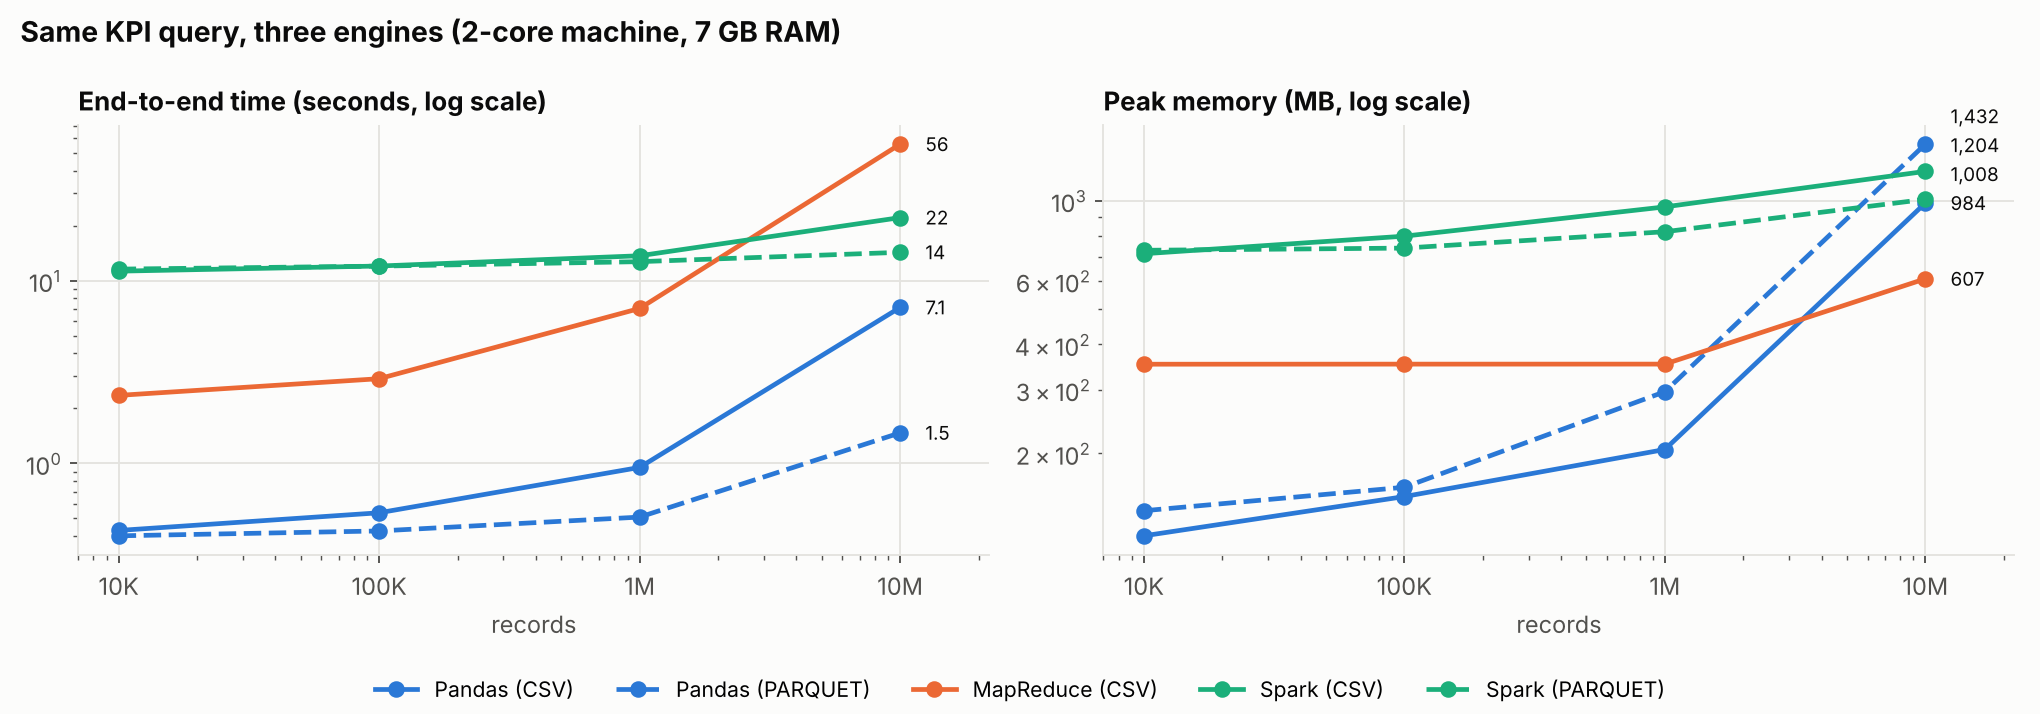

In [13]:
!python src/charts.py >/dev/null 2>&1 || true
display(Image("charts/03_benchmark.png"))

## 4. Marketing Budget Recommendation Engine
1. Daily spend & revenue per platform → fit `log(revenue) = log k + b·log(spend) + season dummies`.
2. *b* < 1 is diminishing returns. Each *b* is shrunk toward the cross-platform mean in proportion to its standard error, and capped at 0.95, because a noisy *b* ≈ 1 would send the whole budget to one platform (see the robustness table).
3. The optimiser splits the budget so the **next rupee earns the same everywhere** (equal marginal ROAS), within 5–45% guard-rails per platform.
4. Bootstrap (300 resamples of days). The recommendation is the **average** of the 300 allocations (bagging), and their spread gives a 90% range.
5. **Offline A/B test**: each candidate split is actually spent for 30 days inside the simulator.

The engine runs on the full **10M-record** dataset.

In [14]:
from recommender import recommend, creative_advice, print_advice, profit_curve
df10 = pd.read_parquet("data/daraz_ads_10M.parquet")
table, comp, curves = recommend(df10, budget=1_000_000)
table[["share_%","PKR","share_low_%","share_high_%","past_ROAS","marginal_ROAS_now","marginal_ROAS_rec","b_raw","b_se","b_shrunk","b_true"]]

,share_%,PKR,share_low_%,share_high_%,past_ROAS,marginal_ROAS_now,marginal_ROAS_rec,b_raw,b_se,b_shrunk,b_true
platform,,,,,,,,,,,
Facebook,31.02,"310,210.73",23.74,40.75,4.41,3.32,3.30,0.80,0.03,0.79,0.75
Instagram,22.39,"223,891.60",15.61,31.91,4.72,3.40,3.31,0.75,0.04,0.75,0.75
Google,36.59,"365,897.67",27.52,45.00,8.51,4.37,3.29,0.52,0.03,0.53,0.50
TikTok,5.00,"50,000.00",5.00,5.00,2.82,2.57,2.71,1.00,0.05,0.95,0.85
YouTube,5.00,"50,000.00",5.00,5.00,1.88,1.76,1.91,0.96,0.08,0.93,0.90


In [15]:
comp

,option,Facebook,Instagram,Google,TikTok,YouTube,predicted_revenue,simulated_revenue,simulated_sd,ROAS,profit_after_ads
0,Recommended (engine),31.02,22.39,36.59,5.00,5.00,"4,783,839.86","4,765,421.00","132,998.66",4.77,"191,355.25"
1,Current mix (history),30.00,20.00,20.00,15.00,15.00,"4,491,666.29","4,485,305.40","84,492.20",4.49,"121,326.35"
2,Equal split (20% each),20.00,20.00,20.00,20.00,20.00,"4,360,537.36","4,308,941.00","114,134.93",4.31,"77,235.25"
3,Proportional to past ROAS,19.75,21.14,38.10,12.62,8.40,"4,667,459.57","4,637,508.00","183,376.09",4.64,"159,377.00"


In [16]:
pc, best, attn = creative_advice(df10)
print_advice(table, comp, best, attn, 1_000_000)


=== MARKETING BUDGET RECOMMENDATION: next Rs 1,000,000 ===
  Google      36.6%  Rs   365,898   (90% range 28-45%)
  Facebook    31.0%  Rs   310,211   (90% range 24-41%)
  Instagram   22.4%  Rs   223,892   (90% range 16-32%)
  TikTok       5.0%  Rs    50,000   (90% range 5-5%)
  YouTube      5.0%  Rs    50,000   (90% range 5-5%)

  Expected revenue: Rs 4,765,421 vs Rs 4,485,305 with the current mix (+Rs 280,116, +6.2%).

  Creative advice (from campaign history):
   - Facebook: run '11.11 / 12.12 Mega Sale' for sales (ROAS 5.1); 'Hansna Mana Hai (Comedy)' gets the most attention (CTR 1.75%).
   - Instagram: run '11.11 / 12.12 Mega Sale' for sales (ROAS 5.6); 'Hansna Mana Hai (Comedy)' gets the most attention (CTR 1.61%).
   - Google: run '11.11 / 12.12 Mega Sale' for sales (ROAS 10.1); 'Hansna Mana Hai (Comedy)' gets the most attention (CTR 3.86%).
   - TikTok: run 'Ramadan & Eid' for sales (ROAS 3.6); 'Hansna Mana Hai (Comedy)' gets the most attention (CTR 1.55%).
   - YouTube: run 'H

**Robustness.** The same engine on each of the four datasets. Same budget, different random draws. The original version (no cap, no shrinkage) broke on 10M: TikTok's *b* came out at 1.00 by chance, the engine put 45% into TikTok, and revenue *fell* below the current mix.

In [17]:
pd.read_csv("results/robustness_by_dataset.csv")

,dataset,method,Facebook,Instagram,Google,TikTok,YouTube,sim_revenue_M
0,10K,"original (no cap, no shrinkage)",30.70,14.30,45.00,5.00,5.00,4.67
1,10K,cap at 0.95 only,30.70,14.30,45.00,5.00,5.00,4.67
2,10K,shrink only,29.00,16.00,45.00,5.00,5.00,4.75
3,10K,engine: shrink+bagging,30.00,16.40,43.60,5.00,5.00,4.67
4,100K,"original (no cap, no shrinkage)",22.90,22.10,45.00,5.00,5.00,4.69
5,100K,cap at 0.95 only,22.90,22.10,45.00,5.00,5.00,4.69
6,100K,shrink only,23.00,22.00,45.00,5.00,5.00,4.72
7,100K,engine: shrink+bagging,23.60,23.00,43.40,5.00,5.00,4.77
8,1M,"original (no cap, no shrinkage)",29.40,32.90,27.70,5.00,5.00,4.74
9,1M,cap at 0.95 only,29.40,32.90,27.70,5.00,5.00,4.74


**Is Rs 1M the right amount?** Revenue here is GMV. If Daraz keeps ~25% of it as contribution margin (assumption: `MARGIN` in `kpis.py`), profit after ad cost peaks well below Rs 1M:

In [18]:
pcurve = profit_curve(curves)
best_b = pcurve.loc[pcurve.profit.idxmax()]
print(f"Profit-maximising budget: Rs {best_b.budget:,.0f}  (profit Rs {best_b.profit:,.0f})")
print(f"At Rs 1,000,000: profit Rs {pcurve.set_index('budget').profit[1_000_000]:,.0f}")
pcurve.iloc[::3]

Profit-maximising budget: Rs 450,000  (profit Rs 260,305)
At Rs 1,000,000: profit Rs 195,966


,budget,revenue,profit
0,100000,"1,106,309.82","176,577.45"
3,250000,"1,956,384.49","239,096.12"
6,400000,"2,635,242.52","258,810.63"
9,550000,"3,231,775.99","257,944.00"
12,700000,"3,778,553.32","244,638.33"
15,850000,"4,293,308.29","223,327.07"
18,1000000,"4,783,862.61","195,965.65"
21,1150000,"5,255,181.66","163,795.41"
24,1300000,"5,710,679.96","127,669.99"
27,1450000,"6,152,831.00","88,207.75"


ok platform_kpis


ok campaign_heatmap


ok response_curves


ok allocation


ok options
/home/claude/daraz-ad-budget-optimizer/src/charts.py:94: RuntimeWarning: invalid value encountered in log10
  gap = (np.log10(hi) - np.log10(lo)) * 0.055


ok benchmark


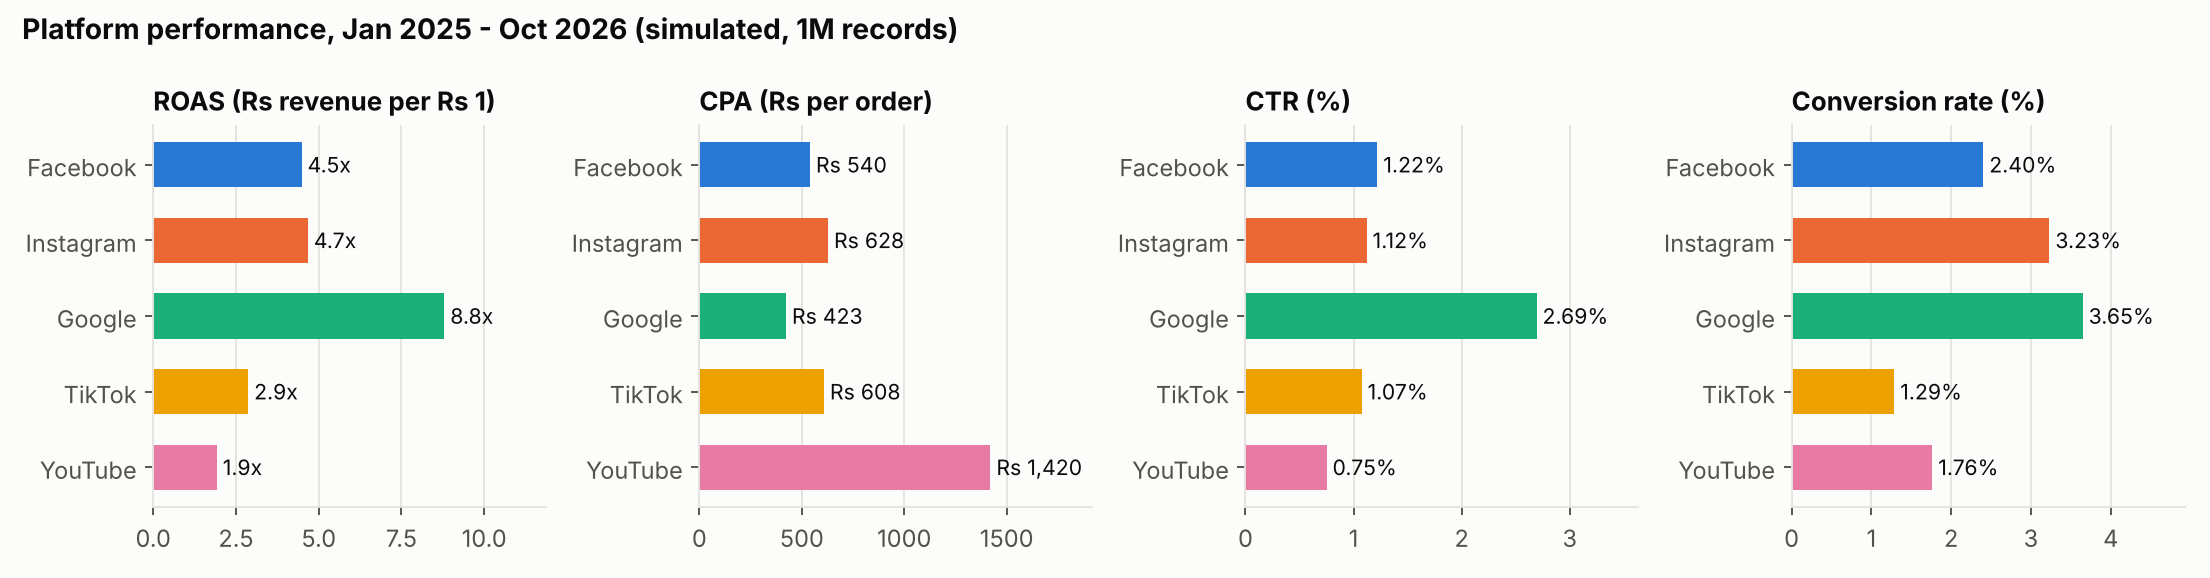

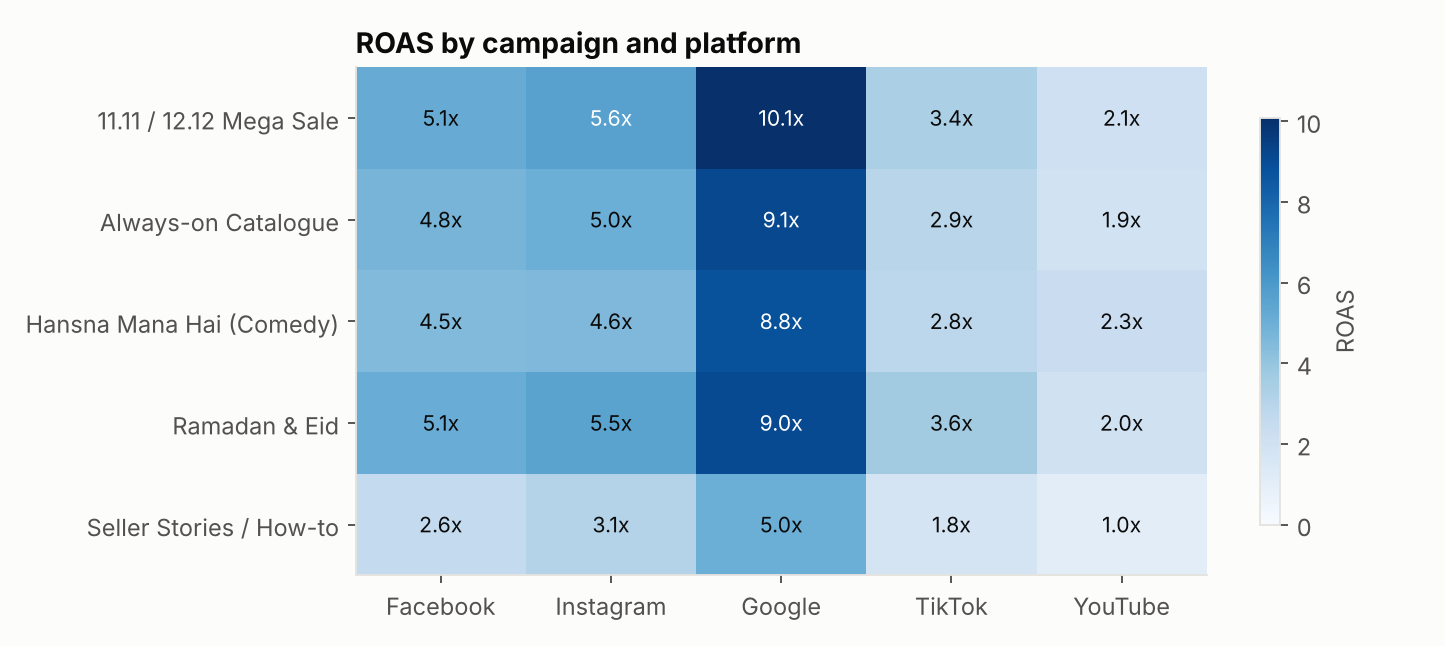

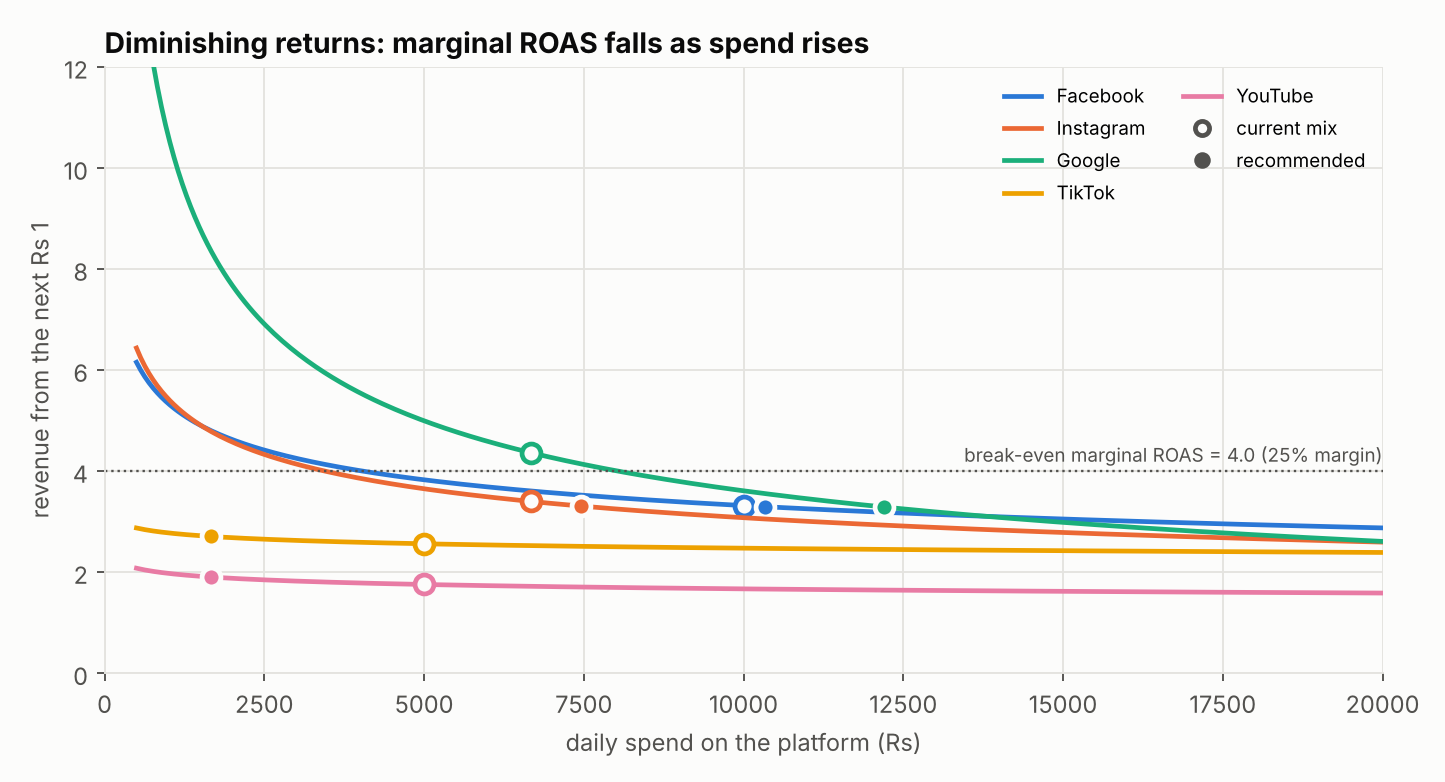

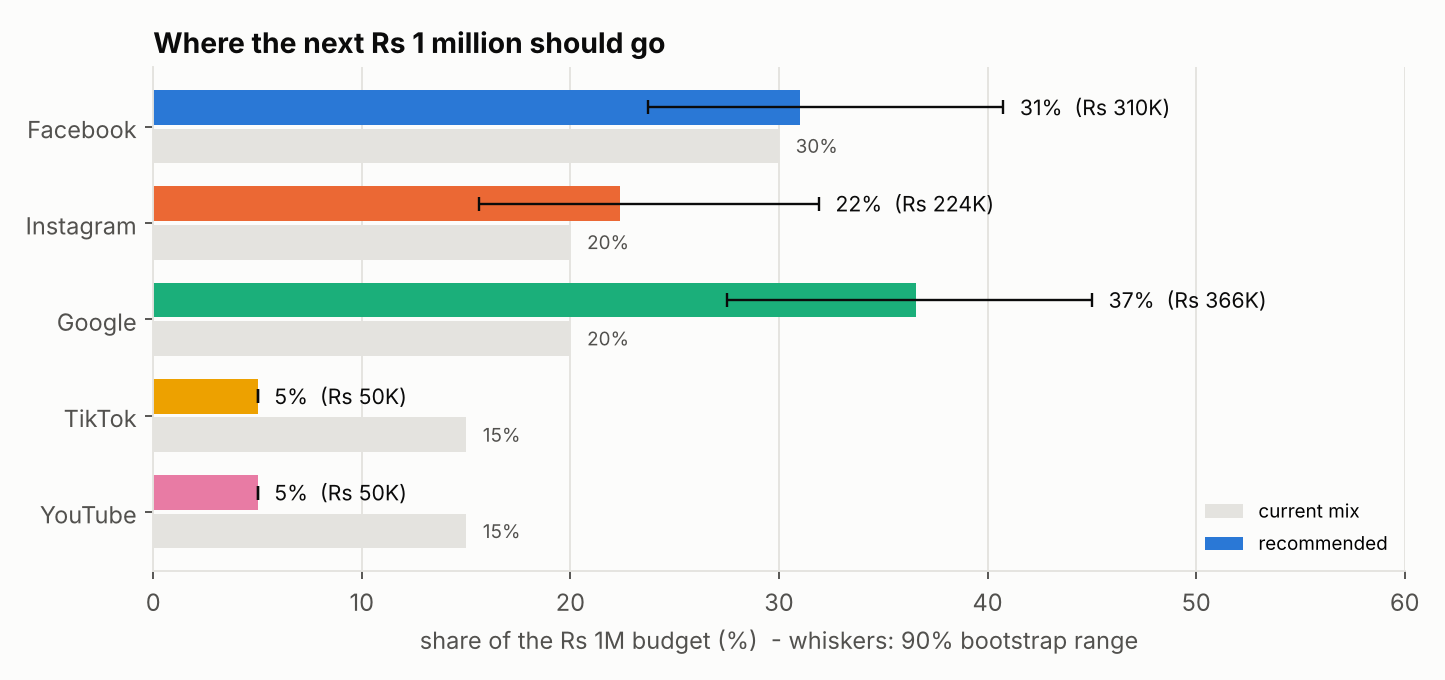

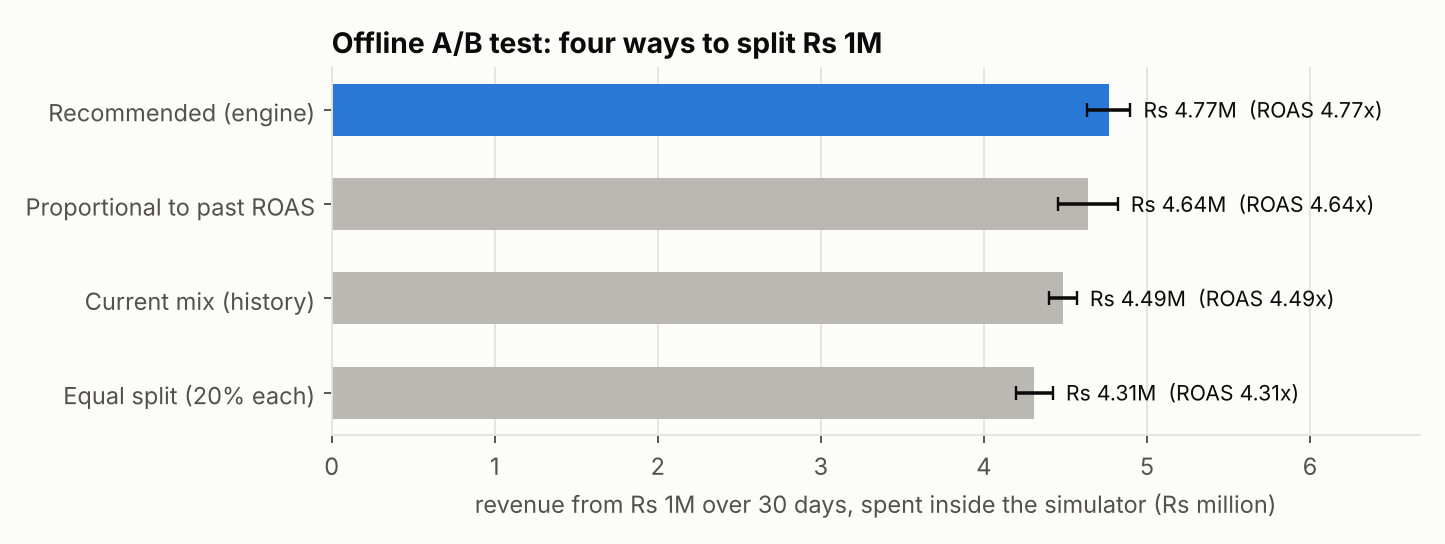

In [19]:
!python src/charts.py
for f in ["01_platform_kpis","02_campaign_roas_heatmap","04_marginal_roas_curves","05_recommended_allocation","06_allocation_ab_test"]:
    display(Image(f"charts/{f}.png"))

## 5. Limitations
* **Simulated data.** The engine is only as good as the assumptions in `config.py`. Its value is the *method*: plug in a real Meta/Google/TikTok export with the same 12 columns and it runs unchanged.
* **Last-click ROAS undervalues YouTube and TikTok.** Project 1 showed entertainment content builds engagement; that brand effect is not in same-day revenue. The 5% floor keeps those channels alive.
* The response curve assumes flat daily pacing and normal (non-sale) days. A sale month lifts every platform, and campaigns should be re-planned around 11.11.
* The benchmark ran on one 2-core, 7 GB machine. A real Hadoop/Spark cluster changes the picture for data larger than RAM.